<a href="https://colab.research.google.com/github/kancharlalavanya09/ML_LAB_2026-27/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**What is Logistic Regression?**

Despite its name, Logistic Regression is a classification algorithm, not a regression one. It's a fundamental supervised learning method used to predict the probability that an input belongs to a specific category.

Its most common use is for binary classification, where there are only two possible outcomes (e.g., Yes/No, 1/0, True/False, Spam/Not Spam).

The core idea is to take a set of input features and output a probability value between 0 and 1. This probability is then used to make a final classification.

**How It Works:** The Sigmoid FunctionLogistic Regression works in two main steps:Linear Step: First, just like linear regression, it calculates a weighted sum of the input features. This result is a single number that can be anything from negative infinity to positive infinity.6Equation:
Logistic (Sigmoid) Step: This is the key part.7 The algorithm passes the linear result (8
) through a special function called the Sigmoid function (or Logistic function).9 This S-shaped function "squishes" any real number into a range between 0 and 1.10Sigmoid Equation: 11

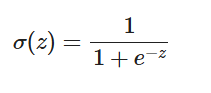

The output of this function is the probability that the input belongs to "Class 1".12If the output is 0.8, it means there's an 80% probability of it being Class 1.13If the output is 0.1, it means there's a 10% probability of it being Class 1.14Finally, a decision threshold (usually 0.5) is used to make the final call:15If Probability 16 ≥
 0.5, predict Class 1.17If Probability 18 <
 0.5, predict Class 0.19

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load the dataset
data = load_breast_cancer()
X = data.data  # Features
y = data.target # Target (0 = malignant, 1 = benign)

# 2. Split the data
# We'll use 70% for training and 30% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3. Scale the features
# Logistic regression (like many algorithms) performs better when features are scaled.
# We fit the scaler on the training data and use it to transform both sets.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Create and Train the Logistic Regression Model
# We instantiate the model and then 'fit' it to our training data.
# 'solver='lbfgs'' is a common default. 'max_iter' might be needed for convergence.
model = LogisticRegression(solver='lbfgs', max_iter=1000)
model.fit(X_train, y_train)

# 5. Make Predictions
# Use the trained model to predict the classes for the unseen test data
y_pred = model.predict(X_test)

# 6. Evaluate the Model
accuracy = accuracy_score(y_test, y_pred)
print(f"--- Model Evaluation ---")
print(f"Accuracy: {accuracy:.4f} (or {accuracy*100:.2f}%)")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


--- Model Evaluation ---
Accuracy: 0.9825 (or 98.25%)

Confusion Matrix:
[[ 62   1]
 [  2 106]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.98      0.98        63
      benign       0.99      0.98      0.99       108

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171

